In [1]:
from pathlib import Path
import numpy as np
import re
from matplotlib import pyplot as plt


def analyze_simulation(directory):

    directory = Path(directory)

    results = []

    for filename in sorted(directory.glob("*.txt")):

        # Read header
        with open(filename, "r") as f:
            header = f.readline().strip()

        # Extract time from "@time=..."
        match = re.search(r"@time=([0-9.eE+-]+)", header)

        if match is None:
            print(f"Could not find time in {filename}")
            continue

        time = float(match.group(1))

        # Read x, y, h, p
        data = np.loadtxt(filename, comments="#")

        x = data[:, 0]
        y = data[:, 1]
        h = data[:, 2]

        # Only consider points where y=0
        mask = y == 0  
        x = x[mask]
        h = h[mask]
        sort_indices = np.argsort(x)
        x = x[sort_indices]
        h = h[sort_indices]

        #plt.plot(x,h,'*')  # To see if points are enough for parabolic fit

        # Location of maximum h
        i = np.argmax(h)
        xmax = x[i]
        hmax = h[i]

        npoints = 5  # Number of points to use for quadratic fit
        # Select npoints centered as much as possible around the maximum
        half = npoints // 2
        i0 = max(0, i - half)
        i1 = min(len(x), i0 + npoints)

        # Correct for boundary cases
        i0 = max(0, i1 - npoints)

        xx = x[i0:i1]
        yy = h[i0:i1]

        # Fit quadratic: y = a*x^2 + b*x + c
        a, b, c = np.polyfit(xx, yy, 2)

        # Vertex of parabola
        xmax = -b / (2 * a)

        hout=h[-1]

        results.append([time, hout, hmax])

    # Sort by time
    results = np.array(results)
    results = results[np.argsort(results[:, 0])]

    return results

In [2]:
40/(0.001**(-1))

0.04

# Compute integrals

In [ ]:
ha=1/2
L=1e2


data = np.loadtxt("2Dcontinuation_pyoomph.txt", skiprows=1)
t=data[:,0]
mask = t==100000.0
data=data[mask,:]

print(len(hout))
print(len(data[:,1]))

#V = data[:, 4]-hout*data[:,3]
L2norm=data[:,7]
V1=data[:,2]
hout = data[:, 3]
V = (data[:, 2]-hout*L**2)/ha**5
invh = data[:,4]
invh2 = data[:,5]
invh3 = data[:,6]
IB0 = hout**3*(invh2-hout*invh3)/ha**5
KB0 = (invh+hout**2*invh3-2*hout*invh2)/ha**3
#IB0 = data[:, 1]/ha**5
#IK0 = data[:, 2]/ha**3
#Hout = data[:, 5]/ha
#Hmax=hmax/ha

imax=35


FileNotFoundError: 2D analysis/pde2path_comparison/obs.txt not found.

# Compare with pde2path continuation

In [ ]:
# pde2path (exploiting radial symmetry to do 1D continuation)
data = np.loadtxt(
    "continuation/2D_continuation.txt",
    delimiter=',',
    unpack=True
)
numrows = len(data[0,:])
KB0pde2path = data[1:, numrows-8]
IB0pde2path = data[1:, numrows-6]
h0out_lim = data[1:, numrows-4]
Vpde2path = data[1:, numrows-11]

(100.0, 449.1516572837651)

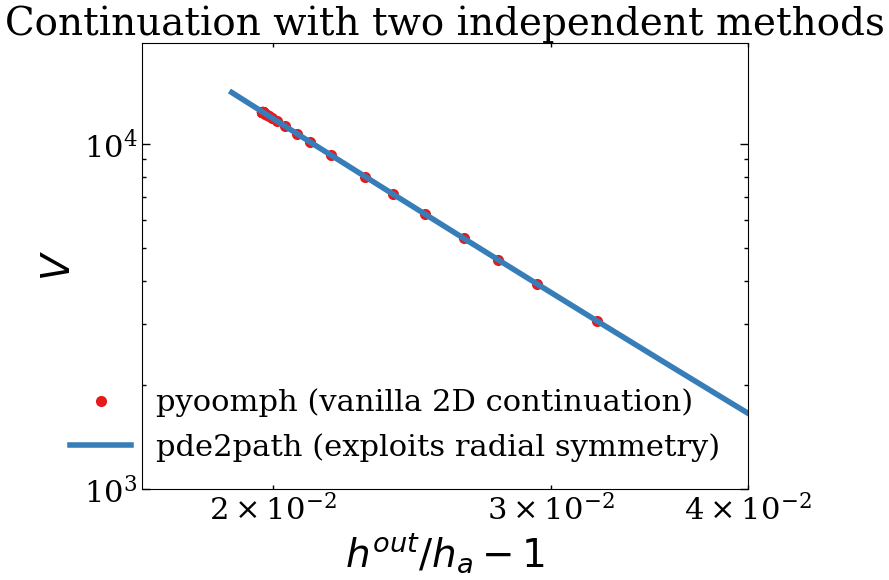

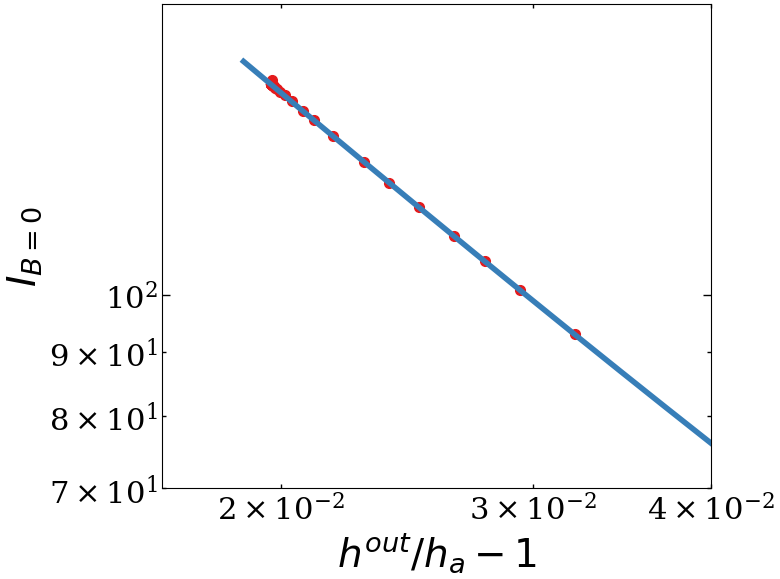

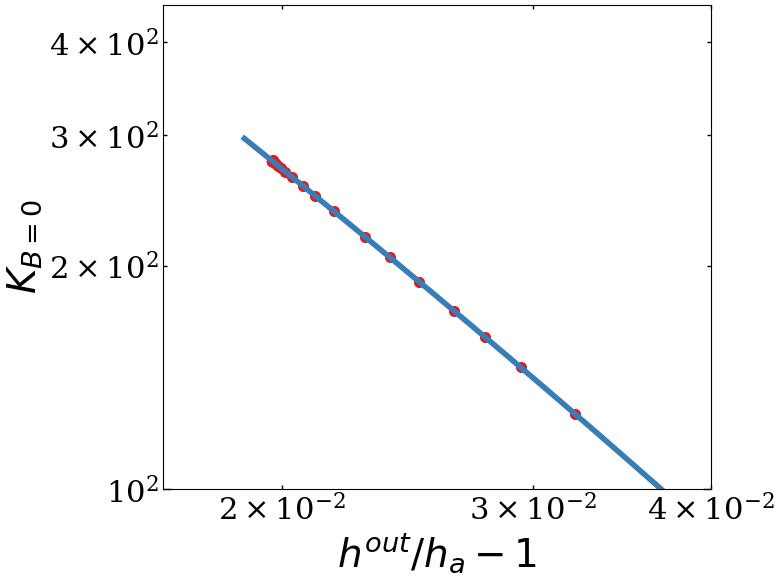

In [ ]:
plt.figure()
# pyoomph
plt.loglog(hout[:imax]/ha-1,V[:imax],'.',label='pyoomph (vanilla 2D continuation)')
# pde2path
plt.plot(h0out_lim-1, Vpde2path,label='pde2path (exploits radial symmetry)')
plt.xlabel('$h^{out}/h_a-1$')
plt.ylabel('$V$')
plt.xlim(right=4e-2)
plt.ylim(bottom=1e3)
plt.legend()
plt.title('Continuation with two independent methods')

plt.figure()
plt.loglog(hout[:imax]/ha-1,IB0[:imax],'.',label='pyoomph (vanilla 2D continuation)')
plt.plot(h0out_lim-1, IB0pde2path,label='pde2path (exploits radial symmetry)')
plt.xlabel('$h^{out}/h_a-1$')
plt.ylabel('$I_{B=0}$')
#plt.legend()
plt.xlim(right=4e-2)
plt.ylim(bottom=70)

plt.figure()
plt.loglog(hout[:imax]/ha-1,KB0[:imax],'.',label='pyoomph (vanilla 2D continuation)')
plt.plot(h0out_lim-1, KB0pde2path,label='pde2path (exploits radial symmetry)')
plt.xlabel('$h^{out}/h_a-1$')
plt.ylabel('$K_{B=0}$')
#plt.legend()
plt.xlim(right=4e-2)
plt.ylim(bottom=1e2)


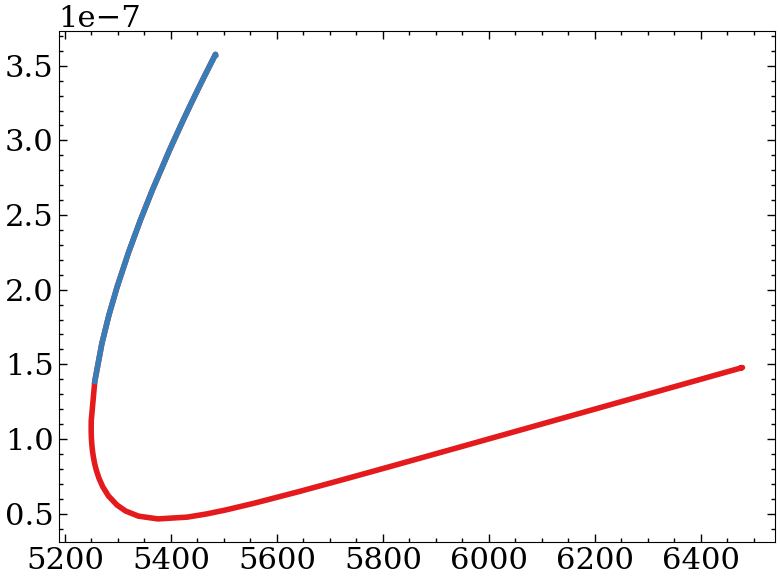

In [ ]:
imax=35
plt.plot(V1,L2norm)
plt.plot(V1[:imax],L2norm[:imax])